# Chi cuadrado: etapa de lactancia y formación de colas

Este notebook responde al segundo criterio de éxito del objetivo de minería de datos: identificar la etapa de lactancia estadísticamente más asociada a la aparición de colas, con un valor p menor a 0.05 en una prueba chi cuadrado de independencia.

Se usa el dataset final de serie de tiempo, donde cada fila es un robot en un bloque de 30 minutos. Como la prueba necesita una etapa por fila, a cada bloque se le asigna su etapa dominante, es decir, la etapa con mayor proporción de ordeños en ese bloque.

En este análisis sí se usan las proporciones de etapa del mismo bloque. No se está prediciendo la cola, solo se mide si la etapa y la cola están relacionadas, por lo que no existe fuga de información.

### 1. Conectar con Google Drive e importar librerías

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, norm

IN_COLAB = "google.colab" in sys.modules

In [2]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  print(RUTA_DATOS)

Mounted at /content/drive


### 2. Parámetros

UMBRAL_COLA es el mismo corte que usan los modelos: un bloque tiene cola si su proporción de posible cola es mayor a 0.5.

VENTANA_HORAS permite repetir el análisis con bloques más grandes, como recomendó el Dr. Aurelio. Con None se usan los bloques originales de 30 minutos; con 1 o 3 se agrupan por hora o por tres horas.

ALFA es el nivel de significancia del criterio de éxito.

In [3]:
UMBRAL_COLA = 0.5
VENTANA_HORAS = None   # None, 1 o 3
ALFA = 0.05

ETAPAS = ["pct_fresca", "pct_alta", "pct_baja", "pct_extendida"]

### 3. Cargar el dataset final

In [4]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

df = load_dataset()

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']


### 4. Preparación para la prueba

1. Se conservan solo los bloques con ordeños y con etapa conocida, porque en los demás no hay etapa ni cola que medir.
2. Si VENTANA_HORAS no es None, los bloques se agrupan por robot y ventana. Las proporciones se promedian ponderando por el número de ordeños de cada bloque.
3. Se asigna la etapa dominante del bloque y se marca si el bloque es puro, es decir, si todos sus ordeños son de una sola etapa.
4. Se crea la variable hay_cola con el mismo umbral que los modelos.

In [5]:
d = df[(df["total_ordenios"] > 0) & (df[ETAPAS].sum(axis=1) > 0)].dropna(subset=["pct_posible_cola"]).copy()
print(f"Bloques con ordeños y etapa conocida: {len(d):,} de {len(df):,}")

if VENTANA_HORAS is not None:
  d["bloque_tiempo"] = d["bloque_tiempo"].dt.floor(f"{VENTANA_HORAS}h")
  cols_pond = ETAPAS + ["pct_primer_parto", "pct_posible_cola"]
  for c in cols_pond:
    d[c] = d[c] * d["total_ordenios"]
  d = d.groupby(["ms", "bloque_tiempo"], as_index=False).agg(
    {**{c: "sum" for c in cols_pond}, "total_ordenios": "sum", "vacas_activas_dia": "first"}
  )
  for c in cols_pond:
    d[c] = d[c] / d["total_ordenios"]
  d["hora"] = d["bloque_tiempo"].dt.hour
  print(f"Bloques de {VENTANA_HORAS} h: {len(d):,}")

d["etapa_dominante"] = d[ETAPAS].idxmax(axis=1).str.replace("pct_", "", regex=False)
d["bloque_puro"] = np.isclose(d[ETAPAS].max(axis=1), 1)
d["hay_cola"] = (d["pct_posible_cola"] > UMBRAL_COLA).astype(int)
d["dia"] = d["bloque_tiempo"].dt.floor("D")

print(f"Bloques puros: {d['bloque_puro'].mean():.1%}")
print(f"Prevalencia de cola: {d['hay_cola'].mean():.1%}")
d["etapa_dominante"].value_counts()

Bloques con ordeños y etapa conocida: 123,040 de 179,850
Bloques puros: 51.2%
Prevalencia de cola: 36.4%


,count
etapa_dominante,
fresca,60203
alta,35771
baja,21049
extendida,6017


### 5. Prueba chi cuadrado de independencia

Hipótesis nula: la proporción de bloques con cola es la misma en todas las etapas de lactancia.

Con más de cien mil bloques el valor p casi siempre sale muy pequeño, por lo que además se reportan tres medidas para interpretar el resultado:

1. V de Cramér, que mide la fuerza de la asociación entre 0 y 1. Valores menores a 0.1 indican una asociación débil.
2. Residuos estandarizados ajustados, que indican qué etapa tiene más colas de las esperadas. Se comparan contra un valor crítico con corrección de Bonferroni.
3. Tasa de cola y lift por etapa. Un lift mayor a 1.2 indica que la etapa tiene al menos 20 % más colas que el promedio.

In [6]:
def prueba_chi2(datos, nombre="Todos los bloques"):
  tabla = pd.crosstab(datos["etapa_dominante"], datos["hay_cola"])
  chi2, p, gl, esperadas = chi2_contingency(tabla)
  n = tabla.values.sum()
  v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

  pf = tabla.sum(axis=1).values[:, None] / n
  pc = tabla.sum(axis=0).values[None, :] / n
  res_aj = (tabla.values - esperadas) / np.sqrt(esperadas * (1 - pf) * (1 - pc))
  z_crit = norm.ppf(1 - ALFA / (2 * tabla.size))

  tasa = tabla[1] / tabla.sum(axis=1)
  resumen = pd.DataFrame({
    "bloques": tabla.sum(axis=1),
    "bloques_con_cola": tabla[1],
    "tasa_cola": tasa,
    "lift": tasa / datos["hay_cola"].mean(),
    "residuo_ajustado": res_aj[:, 1],
  })
  resumen["significativa"] = resumen["residuo_ajustado"].abs() > z_crit
  resumen = resumen.sort_values("residuo_ajustado", ascending=False)

  print(f"=== {nombre} ===")
  print(f"Bloques: {n:,} | Chi² = {chi2:,.2f} | gl = {gl} | p = {p:.3g} | V de Cramér = {v_cramer:.3f}")
  print(f"Valor crítico de los residuos (Bonferroni): ±{z_crit:.2f}")
  print(f"¿Cumple p < {ALFA}? {'Sí' if p < ALFA else 'No'}")
  return tabla, resumen, {"chi2": chi2, "gl": gl, "p": p, "v_cramer": v_cramer, "z_crit": z_crit}

tabla, resumen, stats = prueba_chi2(d)
display(tabla)
display(resumen.round(3))

=== Todos los bloques ===
Bloques: 123,040 | Chi² = 38.15 | gl = 3 | p = 2.63e-08 | V de Cramér = 0.018
Valor crítico de los residuos (Bonferroni): ±2.73
¿Cumple p < 0.05? Sí


hay_cola,0,1
etapa_dominante,,
alta,22437,13334
baja,13241,7808
extendida,3981,2036
fresca,38551,21652


,bloques,bloques_con_cola,tasa_cola,lift,residuo_ajustado,significativa
etapa_dominante,,,,,,
alta,35771,13334,0.373,1.023,3.923,True
baja,21049,7808,0.371,1.018,2.182,False
fresca,60203,21652,0.360,0.987,-3.355,True
extendida,6017,2036,0.338,0.929,-4.294,True


### 6. Visualización

La gráfica de la izquierda muestra la tasa de cola por etapa contra el promedio general. La de la derecha muestra los residuos ajustados: las barras que salen de las líneas punteadas son las etapas con una diferencia significativa.

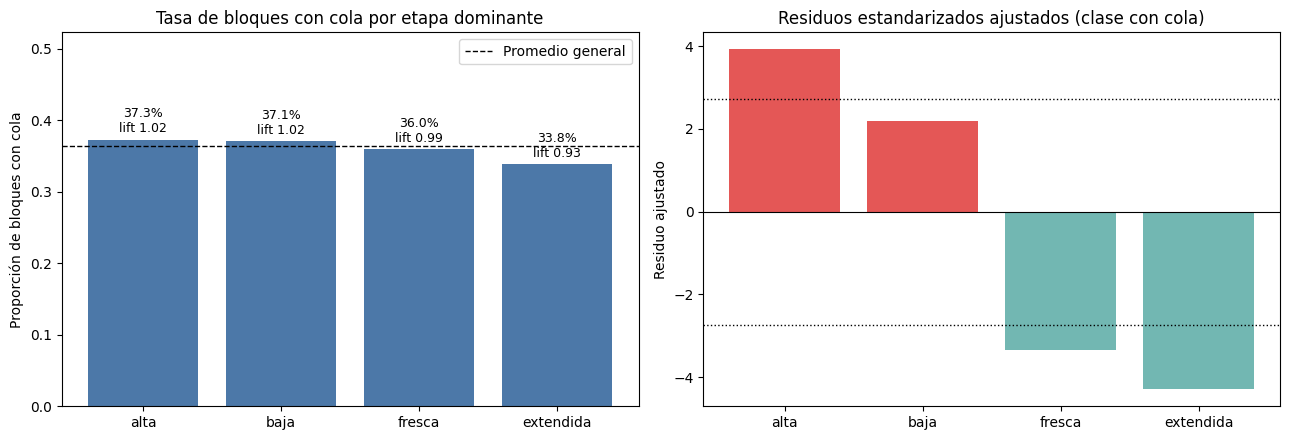

In [7]:
orden = resumen.index
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(orden, resumen.loc[orden, "tasa_cola"], color="#4C78A8")
axes[0].axhline(d["hay_cola"].mean(), color="black", linestyle="--", linewidth=1, label="Promedio general")
for i, (t, l) in enumerate(zip(resumen.loc[orden, "tasa_cola"], resumen.loc[orden, "lift"])):
  axes[0].text(i, t + 0.01, f"{t:.1%}\nlift {l:.2f}", ha="center", fontsize=9)
axes[0].set_title("Tasa de bloques con cola por etapa dominante")
axes[0].set_ylabel("Proporción de bloques con cola")
axes[0].set_ylim(0, min(1, resumen["tasa_cola"].max() + 0.15))
axes[0].legend()

colores = ["#E45756" if r > 0 else "#72B7B2" for r in resumen.loc[orden, "residuo_ajustado"]]
axes[1].bar(orden, resumen.loc[orden, "residuo_ajustado"], color=colores)
axes[1].axhline(stats["z_crit"], color="black", linestyle=":", linewidth=1)
axes[1].axhline(-stats["z_crit"], color="black", linestyle=":", linewidth=1)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Residuos estandarizados ajustados (clase con cola)")
axes[1].set_ylabel("Residuo ajustado")

plt.tight_layout()
plt.show()

### 7. Revisión de robustez con bloques puros

En los bloques donde se ordeñaron vacas de varias etapas, la etapa dominante pierde información. Se repite la prueba solo con los bloques donde todos los ordeños son de una misma etapa. Si la conclusión se mantiene, el resultado no depende de cómo se eligió la etapa dominante.

In [8]:
tabla_pura, resumen_puro, stats_puro = prueba_chi2(d[d["bloque_puro"]], "Solo bloques puros")
display(resumen_puro.round(3))

=== Solo bloques puros ===
Bloques: 62,936 | Chi² = 53.33 | gl = 3 | p = 1.56e-11 | V de Cramér = 0.029
Valor crítico de los residuos (Bonferroni): ±2.73
¿Cumple p < 0.05? Sí


,bloques,bloques_con_cola,tasa_cola,lift,residuo_ajustado,significativa
etapa_dominante,,,,,,
alta,18615,3828,0.206,1.062,4.971,True
fresca,27202,5326,0.196,1.012,1.237,False
baja,12714,2297,0.181,0.933,-4.120,True
extendida,4405,731,0.166,0.857,-4.810,True


### 8. Prueba chi cuadrado por primer parto

El Business Understanding menciona que las vacas de primer parto suelen esperar más en la cola. Se clasifica cada bloque según si la mayoría de sus ordeños son de vacas de primer parto y se repite la prueba.

In [9]:
d_pp = d.dropna(subset=["pct_primer_parto"]).copy()
d_pp["etapa_dominante"] = np.where(d_pp["pct_primer_parto"] > 0.5, "primer_parto", "multipara")
tabla_pp, resumen_pp, stats_pp = prueba_chi2(d_pp, "Primer parto contra multíparas")
display(resumen_pp.round(3))

=== Primer parto contra multíparas ===
Bloques: 123,040 | Chi² = 233.11 | gl = 1 | p = 1.25e-52 | V de Cramér = 0.044
Valor crítico de los residuos (Bonferroni): ±2.50
¿Cumple p < 0.05? Sí


,bloques,bloques_con_cola,tasa_cola,lift,residuo_ajustado,significativa
etapa_dominante,,,,,,
multipara,87194,32941,0.378,1.037,15.275,True
primer_parto,35846,11889,0.332,0.910,-15.275,True


### 9. Regresión logística con la configuración de LogisticRegression

La prueba chi cuadrado no considera otras variables. Si las vacas de alguna etapa se ordeñan más en horas pico, la prueba podría estar midiendo la hora y no la etapa. Para confirmarlo se ajusta una regresión logística con la misma configuración que la celda de significancia estadística de LogisticRegression.ipynb:

1. Mismas variables: rezagos del bloque anterior (total de ordeños, duración, ocupación, hubo ordeños y porcentaje de cola), hora y día en seno y coseno, robot y temporada como dummies con drop first, y las variables de ordeño e incidencias del bloque.
2. Mismo preprocesamiento: imputación con 0 y StandardScaler en las numéricas; las dummies pasan sin cambio.
3. Mismo ajuste: statsmodels Logit con constante, máximo 200 iteraciones y errores estándar agrupados por día.
4. Misma variable objetivo: cola si pct_posible_cola es mayor a 0.5.

Solo cambian dos cosas para que el efecto medido sea el de la etapa:

1. Se usan solo los bloques con ordeños y etapa conocida. En los bloques vacíos las proporciones de etapa valen 0 y terminan midiendo si hubo ordeños.
2. Se deja fuera pct_baja como categoría de referencia, porque las cuatro proporciones suman 1.

USAR_VACAS controla si se incluye vacas_activas_dia. En LogisticRegression.ipynb esa variable termina fuera del modelo aunque el parámetro esté activo, por eso aquí el valor por defecto es False para replicar su corrida.

La prueba de Wald conjunta da un chi cuadrado que indica si la etapa aporta información después de los controles. Los odds ratio se reportan por una desviación estándar, como en el modelo original, y también por cada 10 puntos porcentuales más de esa etapa en el bloque, en lugar de la etapa baja.

In [10]:
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

TARGET = "pct_posible_cola"
USAR_VACAS = False

# --- Mismas variables derivadas que LogisticRegression.ipynb (se calculan sobre la malla completa)
r = df.sort_values(["ms", "bloque_tiempo"]).reset_index(drop=True)
g = r.groupby("ms")
contiguo = (r["bloque_tiempo"] - g["bloque_tiempo"].shift(1)) == pd.Timedelta("30min")

COLS_ORDENIO = ["total_ordenios", "duracion_total_min", "pct_ocupacion_robot", "hubo_ordenios"]
cols_lag = [c for c in COLS_ORDENIO if c in r.columns]
for c in cols_lag:
  r[f"{c}_anterior"] = g[c].shift(1).where(contiguo)
r["pct_cola_anterior"] = g[TARGET].shift(1).where(contiguo)

r["hora_sin"] = np.sin(2 * np.pi * r["hora"] / 24)
r["hora_cos"] = np.cos(2 * np.pi * r["hora"] / 24)
r["dia_sin"] = np.sin(2 * np.pi * r["dia_semana"] / 7)
r["dia_cos"] = np.cos(2 * np.pi * r["dia_semana"] / 7)
r["cola"] = (r[TARGET] > UMBRAL_COLA).astype("float32")

r = r.sort_values(["bloque_tiempo", "ms"], kind="stable").reset_index(drop=True)

# --- Diferencias con LogisticRegression.ipynb: solo bloques con ordeños y etapa conocida
con_etapa = (r["total_ordenios"] > 0) & (r[ETAPAS].sum(axis=1) > 0) & r[TARGET].notna()
r_clean = r[con_etapa].drop(columns=cols_lag).dropna(subset=["pct_cola_anterior"]).reset_index(drop=True)
r_clean = pd.get_dummies(r_clean, columns=["ms", "temporada"], dtype="float32", drop_first=True)

DROP_COLUMNS = [TARGET, "bloque_tiempo", "cola", "produccion_promedio", "sin_etapa",
                "hora", "dia_semana", "pct_baja"]
if not USAR_VACAS:
  DROP_COLUMNS.append("vacas_activas_dia")
y_r = r_clean["cola"].values
X_r = r_clean.drop(columns=[c for c in DROP_COLUMNS if c in r_clean.columns])

# Columnas sin variación en estos bloques (harían singular la matriz)
constantes = [c for c in X_r.columns if X_r[c].nunique(dropna=True) <= 1]
if constantes:
  print(f"Se quitan por no tener variación: {constantes}")
  X_r = X_r.drop(columns=constantes)

# Columnas idénticas a otra (colinealidad perfecta)
duplicadas = X_r.columns[X_r.T.duplicated()].tolist()
if duplicadas:
  print(f"Se quitan por ser idénticas a otra columna: {duplicadas}")
  X_r = X_r.drop(columns=duplicadas)
print(f"Bloques: {len(X_r):,} | Variables: {X_r.shape[1]}")
print(list(X_r.columns))

Bloques: 123,040 | Variables: 24
['patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_extendida', 'hubo_lavado', 'ordenios_otros_robots', 'min_desde_alimento', 'total_ordenios_anterior', 'duracion_total_min_anterior', 'pct_ocupacion_robot_anterior', 'hubo_ordenios_anterior', 'pct_cola_anterior', 'hora_sin', 'hora_cos', 'dia_sin', 'dia_cos', 'ms_VMS 2', 'ms_VMS 3', 'temporada_otoño', 'temporada_primavera', 'temporada_verano']


In [11]:
# --- Mismo preprocesamiento: imputar 0 + StandardScaler en numéricas, dummies sin cambio
dummies = [c for c in X_r.columns if c.startswith(("ms_", "temporada_"))]
numericas = [c for c in X_r.select_dtypes(include="number").columns if c not in dummies]

pre = ColumnTransformer(
  transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value=0)),
                      ("scaler", StandardScaler())]), numericas),
    ("bin", "passthrough", dummies),
  ],
  remainder="drop",
  verbose_feature_names_out=False,
)
pre.set_output(transform="pandas")

Z = pre.fit_transform(X_r).astype("float64")       # escalado con todo el periodo (análisis explicativo)
Zc = sm.add_constant(Z, has_constant="add")
grupos_dia = pd.factorize(r_clean["bloque_tiempo"].dt.floor("D"))[0]

logit = sm.Logit(y_r, Zc).fit(disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": grupos_dia})
print(f"Observaciones: {int(logit.nobs):,} | días (clusters): {grupos_dia.max() + 1} | Pseudo R²: {logit.prsquared:.4f}")

df_stats = pd.DataFrame({
  "Feature": logit.params.index,
  "Coeficiente": logit.params.values,
  "Std Error (robusto)": logit.bse.values,
  "t (z de Wald)": logit.tvalues.values,
  "p-value": logit.pvalues.values,
})
df_stats["Significativo (p < 0.05)"] = df_stats["p-value"] < ALFA
df_stats = df_stats.reindex(df_stats["t (z de Wald)"].abs().sort_values(ascending=False).index)
display(df_stats.round(4))

Observaciones: 123,040 | días (clusters): 1235 | Pseudo R²: 0.1025


,Feature,Coeficiente,Std Error (robusto),t (z de Wald),p-value,Significativo (p < 0.05)
9,ordenios_otros_robots,0.4898,0.0101,48.4150,0.0000,True
1,patadas_totales,0.2169,0.0068,32.0845,0.0000,True
15,pct_cola_anterior,0.1824,0.0102,17.8261,0.0000,True
0,const,-0.5108,0.0308,-16.5768,0.0000,True
4,pct_primer_parto,-0.0987,0.0069,-14.2180,0.0000,True
21,ms_VMS 3,-0.2464,0.0195,-12.6141,0.0000,True
20,ms_VMS 2,-0.1668,0.0195,-8.5665,0.0000,True
5,pct_fresca,-0.0766,0.0090,-8.5161,0.0000,True
14,hubo_ordenios_anterior,-0.0806,0.0105,-7.6463,0.0000,True
11,total_ordenios_anterior,0.1181,0.0189,6.2544,0.0000,True


In [12]:
# --- Chi² de Wald conjunto de la etapa y odds ratio
wald = logit.wald_test("pct_fresca = 0, pct_alta = 0, pct_extendida = 0", scalar=True)
print(f"Wald chi² de la etapa (con los controles de LogisticRegression) = {float(wald.statistic):,.2f} | "
      f"gl = 3 | p = {float(wald.pvalue):.3g}")

vars_etapa = ["pct_fresca", "pct_alta", "pct_extendida", "pct_primer_parto"]
escala = pd.Series(pre.named_transformers_["num"].named_steps["scaler"].scale_, index=numericas)[vars_etapa]
coef = logit.params[vars_etapa]
ic = logit.conf_int().loc[vars_etapa]
odds = pd.DataFrame({
  "coeficiente (estandarizado)": coef,
  "OR por 1 desv. est.": np.exp(coef),
  "OR por +10 pp": np.exp(coef / escala * 0.1),
  "IC 2.5 % (+10 pp)": np.exp(ic[0] / escala * 0.1),
  "IC 97.5 % (+10 pp)": np.exp(ic[1] / escala * 0.1),
  "p": logit.pvalues[vars_etapa],
})
odds["significativa"] = odds["p"] < ALFA
display(odds.round(4))

Wald chi² de la etapa (con los controles de LogisticRegression) = 129.91 | gl = 3 | p = 5.65e-28


,coeficiente (estandarizado),OR por 1 desv. est.,OR por +10 pp,IC 2.5 % (+10 pp),IC 97.5 % (+10 pp),p,significativa
pct_fresca,-0.0766,0.9263,0.9809,0.9766,0.9853,0.0000,True
pct_alta,-0.0023,0.9977,0.9994,0.9946,1.0041,0.7986,False
pct_extendida,0.0033,1.0033,1.0014,0.9950,1.0079,0.6590,False
pct_primer_parto,-0.0987,0.9060,0.9754,0.9721,0.9788,0.0000,True


### 10. Resumen del criterio de éxito

La tabla reúne los resultados para documentarlos en el reporte. El criterio se cumple si el valor p de la prueba chi cuadrado es menor a 0.05. La etapa más asociada es la que tiene el residuo ajustado positivo más alto y significativo; se recomienda que además tenga un lift mayor a 1.2 y que la regresión con controles apunte en la misma dirección.

Nota para el reporte: la conclusión es a nivel bloque, por ejemplo, los bloques dominados por vacas frescas presentan más colas. No permite afirmar que cada vaca de esa etapa espere más; para eso se necesitaría el análisis a nivel ordeño.

In [13]:
positivas = resumen[(resumen["residuo_ajustado"] > 0) & resumen["significativa"]]
etapa_top = positivas.index[0] if len(positivas) else "ninguna"

criterio = pd.DataFrame({
  "Prueba": ["Chi² etapa dominante", "Chi² solo bloques puros", "Chi² primer parto", "Wald chi² etapa con controles"],
  "Chi²": [stats["chi2"], stats_puro["chi2"], stats_pp["chi2"], float(wald.statistic)],
  "p": [stats["p"], stats_puro["p"], stats_pp["p"], float(wald.pvalue)],
  "V de Cramér": [stats["v_cramer"], stats_puro["v_cramer"], stats_pp["v_cramer"], np.nan],
})
criterio["Cumple p < 0.05"] = criterio["p"] < ALFA
display(criterio.round(4))

print(f"Etapa más asociada a la cola: {etapa_top}")
if etapa_top != "ninguna":
  print(f"Tasa de cola: {resumen.loc[etapa_top, 'tasa_cola']:.1%} | Lift: {resumen.loc[etapa_top, 'lift']:.2f} | "
        f"Residuo ajustado: {resumen.loc[etapa_top, 'residuo_ajustado']:.2f}")

,Prueba,Chi²,p,V de Cramér,Cumple p < 0.05
0,Chi² etapa dominante,38.1478,0.0,0.0176,True
1,Chi² solo bloques puros,53.3294,0.0,0.0291,True
2,Chi² primer parto,233.1140,0.0,0.0435,True
3,Wald chi² etapa con controles,129.9135,0.0,NaN,True


Etapa más asociada a la cola: alta
Tasa de cola: 37.3% | Lift: 1.02 | Residuo ajustado: 3.92
